# Laboratorio 21 — Agrupamiento sobre tres casos reales

Sin variable respuesta, el criterio de éxito lo pone el analista: **un agrupamiento no es
correcto ni incorrecto, es útil o no para la decisión que hay que tomar.** Este laboratorio
aplica k-medias, el jerárquico aglomerativo y DBSCAN sobre tres conjuntos que muestran esa
idea desde lados distintos:

1. **Parcelas y cultivos.** Hay estructura real, y la partición que prefiere la silueta no
   es la que sirve.
2. **Estados y delitos.** No hay regiones densas separadas, y aun así los grupos sirven.
3. **Clientes de una agencia de viajes.** Hay estructura nítida, pero la produce la
   codificación de los datos.

El enunciado completo es el de la serie de ejercicios de agrupamiento: cada inciso se
reproduce acá antes de su celda. Las celdas marcadas `# TODO:` deben completarse; el resto
es andamiaje y se ejecuta sin modificar. **Cada inciso cierra con una interpretación** en la celda
`**Respuesta:**`: una cifra sin lectura no responde el inciso.

Si el tiempo no alcanza, del ejercicio 1 se priorizan los incisos (a) a (d), y del 3, los
incisos (a), (c) y (e).

## Antes de empezar: el índice de Rand ajustado

Varios incisos piden comparar **dos particiones del mismo conjunto de observaciones**: la de
k-medias contra la de Ward, la de datos estandarizados contra la de datos sin estandarizar,
o un agrupamiento contra una etiqueta externa como el cultivo. Para eso se usa el **índice
de Rand ajustado** (*adjusted Rand index*, $\operatorname{ARI}$).

**Comparar por pares, no por nombres.** Los números de grupo son arbitrarios: la partición
$(0,0,1,1)$ y la $(1,1,0,0)$ son la misma. Por eso no se comparan las etiquetas una a una,
sino **los pares de observaciones**. Sobre un par $\{i,i'\}$, dos particiones están de
acuerdo si las dos lo ponen en el mismo grupo, o si las dos lo separan. El **índice de
Rand** es la proporción de pares en que están de acuerdo:

$$
\operatorname{RI}=\frac{\text{pares en que las dos particiones están de acuerdo}}{\binom{n}{2}} .
$$

**Por qué hay que ajustarlo.** Con varios grupos, la mayoría de los pares quedan separados
en cualquier partición, y dos particiones **al azar** ya están de acuerdo en muchos pares:
el $\operatorname{RI}$ sale alto aunque no haya ninguna relación. El ajuste le resta el
valor esperado bajo particiones al azar con los mismos tamaños de grupo, y reescala para
que el máximo valga $1$:

$$
\operatorname{ARI}=\frac{\operatorname{RI}-\mathbb E[\operatorname{RI}]}{\max\operatorname{RI}-\mathbb E[\operatorname{RI}]} .
$$

**Cómo se lee.**

| $\operatorname{ARI}$ | Significado |
|---|---|
| $1$ | Las dos particiones son idénticas, aunque los grupos tengan otros números |
| cerca de $0$ | Coinciden lo mismo que dos particiones al azar |
| negativo | Acuerdo inferior al esperado al azar; no es idéntico a $0$ |

Es simétrico —da lo mismo cuál partición va primero— y no exige que las dos tengan la misma
cantidad de grupos. **No dice cuál de las dos particiones es mejor**: solo cuánto se
parecen. Para ver **dónde** difieren se mira la tabla cruzada, `pd.crosstab(a, b)`.

En `scikit-learn`: `adjusted_rand_score(etiquetas_a, etiquetas_b)`. La celda siguiente lo
muestra sobre tres casos.

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, rand_score

a = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
b = np.array([2, 2, 2, 0, 0, 0, 1, 1, 1])     # la misma partición, con otros números
c = np.array([0, 0, 1, 1, 1, 1, 2, 2, 2])     # una observación cambiada de grupo
print(f"a contra b: RI = {rand_score(a, b):.3f}, ARI = {adjusted_rand_score(a, b):.3f}")
print(f"a contra c: RI = {rand_score(a, c):.3f}, ARI = {adjusted_rand_score(a, c):.3f}")
print(pd.crosstab(a, c, rownames=["a"], colnames=["c"]))

# Dos particiones al azar de 1000 observaciones en 10 grupos
rng = np.random.default_rng(0)
u, v = rng.integers(0, 10, 1000), rng.integers(0, 10, 1000)
print(f"\nAl azar:    RI = {rand_score(u, v):.3f}, ARI = {adjusted_rand_score(u, v):.3f}")

a contra b: RI = 1.000, ARI = 1.000
a contra c: RI = 0.861, ARI = 0.643
c  0  1  2
a         
0  2  1  0
1  0  3  0
2  0  0  3

Al azar:    RI = 0.820, ARI = -0.001


Con una sola observación cambiada de grupo, el $\operatorname{ARI}$ baja bastante más que el
$\operatorname{RI}$: en $n=9$, un cambio afecta a muchos pares. Con dos particiones al azar,
el $\operatorname{RI}$ supera $0{,}8$ sin que haya ninguna relación, y el $\operatorname{ARI}$
queda en $0$. **Por eso se reporta el ajustado.**

## 0. Preparación

In [2]:
from __future__ import annotations

from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEMILLA = 0

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [3]:
# Carga de datos del curso. No hace falta modificar nada.

# Carpeta data/ del repositorio del curso
URL_DATOS = ("https://raw.githubusercontent.com/"
             "ucudal/Machine-Learning---Ingenieria-en-IA-y-CD/main/data/")


def _token_github() -> str | None:
    """Token de GitHub para leer el repositorio del curso, que es privado.

    En Colab se toma del secreto GITHUB_TOKEN (icono de la llave, en la barra
    lateral); fuera de Colab, de la variable de entorno del mismo nombre.
    """
    try:
        from google.colab import userdata  # type: ignore
        return userdata.get("GITHUB_TOKEN")
    except Exception:
        import os
        return os.environ.get("GITHUB_TOKEN")


def ruta_del_dato(nombre: str) -> str:
    """Devuelve la ruta local del archivo, este donde este el notebook.

    Busca el archivo junto al notebook y en las carpetas `data/` de hasta tres
    niveles superiores; si no esta, lo descarga del repositorio del curso a
    `data/`; y si no se puede, en Colab ofrece subirlo a mano.
    """
    candidatas = [Path(nombre), Path("data") / nombre]
    for arriba in ("..", "../..", "../../.."):
        candidatas += [Path(arriba) / nombre, Path(arriba) / "data" / nombre]
    for ruta in candidatas:
        if ruta.exists():
            print(f"Cargado desde {ruta}")
            return str(ruta)

    destino = Path("data")
    destino.mkdir(exist_ok=True)
    ruta = destino / nombre
    pedido = urllib.request.Request(URL_DATOS + nombre)
    token = _token_github()
    if token:
        pedido.add_header("Authorization", f"token {token}")
    try:
        with urllib.request.urlopen(pedido, timeout=30) as respuesta:
            ruta.write_bytes(respuesta.read())
        print(f"Descargado del repositorio del curso a {ruta}")
        return str(ruta)
    except Exception:
        pass

    try:
        from google.colab import files  # type: ignore
    except ImportError:
        raise FileNotFoundError(
            f"No se encontro {nombre}. Dejarlo en una carpeta 'data/' junto al notebook.")

    print(f"Falta {nombre}: seleccionar el archivo para subirlo.")
    subidos = files.upload()
    ruta.write_bytes(subidos[nombre])
    return str(ruta)

### Funciones auxiliares

Andamiaje común a los tres ejercicios. `km` fija la configuración de k-medias de toda la
serie, `KMeans(n_clusters=K, n_init=10, random_state=0)`; `perfil` arma la tabla de medias
por grupo; `inercia` calcula $J$ para **cualquier** partición, no solo la de k-medias; y
`graficar_k_distancias` dibuja el gráfico de k-distancias de DBSCAN.

In [4]:
def km(X: np.ndarray, K: int, semilla: int = SEMILLA) -> KMeans:
    """k-medias con la configuración de la serie. Devuelve el modelo ajustado."""
    return KMeans(n_clusters=K, n_init=10, random_state=semilla).fit(X)


def perfil(datos: pd.DataFrame, etiquetas: np.ndarray) -> pd.DataFrame:
    """Media de cada columna de `datos` por grupo, y el tamaño del grupo en la columna `n`."""
    etiquetas = np.asarray(etiquetas)
    tabla = datos.groupby(etiquetas).mean()
    tabla["n"] = pd.Series(etiquetas).value_counts().sort_index().to_numpy()
    return tabla


def inercia(X: np.ndarray, etiquetas: np.ndarray) -> float:
    """Inercia J de una partición cualquiera: suma de distancias cuadradas al centroide."""
    etiquetas = np.asarray(etiquetas)
    return float(sum(((X[etiquetas == g] - X[etiquetas == g].mean(axis=0)) ** 2).sum()
                     for g in np.unique(etiquetas)))


def graficar_k_distancias(X: np.ndarray, m_pts: int, eps: tuple = ()) -> np.ndarray:
    """Distancia de cada observación a su m_pts-ésima más cercana, contándose a sí misma,
    en orden decreciente. Grafica la curva con líneas horizontales en los `eps` dados."""
    d = NearestNeighbors(n_neighbors=m_pts).fit(X).kneighbors(X)[0][:, -1]
    d = np.sort(d)[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    ax.plot(np.arange(1, len(d) + 1), d, color="#19326E")
    for e in eps:
        ax.axhline(e, ls="--", lw=1, color="#CD742A")
    ax.set_xlabel("observaciones, ordenadas")
    ax.set_ylabel(f"distancia al vecino {m_pts}")
    ax.set_title("Gráfico de k-distancias")
    plt.show()
    return d

### Los datos

| Archivo | Forma | Ejercicio |
|---|---|---|
| `crop_recommendation.csv` | $2200\times8$ | 1. Siete features de suelo y clima por parcela, y el cultivo recomendado |
| `usarrests.csv` | $50\times5$ | 2. Tasas de arresto por tres delitos y población urbana, por estado de EE. UU., 1973 |
| `travel_insurance.csv` | $1987\times9$ | 3. Clientes de una agencia de viajes y si compraron el seguro |

> **Antes de ejecutar.** Los tres archivos están en la carpeta `data/` del repositorio del
> curso. Abriendo el notebook desde el repositorio clonado, la celda de carga los encuentra.
> En Colab los descarga del repositorio, que es privado: hace falta cargar un token de
> GitHub con acceso de lectura como secreto `GITHUB_TOKEN` (icono de la llave, en la barra
> lateral). Sin token, la celda ofrece subir cada archivo a mano.

La celda siguiente los carga, traduce los cultivos y codifica los binarios del ejercicio 3
con $1$ para sector privado y para cada «sí».

**Datos de esta ejecución:** los tres CSV se incluyen en `data/`; no se necesita token. Se usaron versiones públicas de Crop Recommendation y Travel Insurance de Kaggle y USArrests de Rdatasets/R. Coinciden con los tamaños y esquemas de la consigna. En Travel Insurance se quitó solo el índice de exportación, y en USArrests se llamó `Estado` a la columna de nombres. No se fabricaron observaciones. Las fuentes y hashes se documentan al final.

In [5]:
NOMBRES_CULTIVO = {
    "rice": "arroz", "maize": "maíz", "chickpea": "garbanzo", "kidneybeans": "poroto rojo",
    "pigeonpeas": "guandú", "mothbeans": "poroto moth", "mungbean": "poroto mung",
    "blackgram": "poroto negro", "lentil": "lenteja", "pomegranate": "granada",
    "banana": "banana", "mango": "mango", "grapes": "uva", "watermelon": "sandía",
    "muskmelon": "melón", "apple": "manzana", "orange": "naranja", "papaya": "papaya",
    "coconut": "coco", "cotton": "algodón", "jute": "yute", "coffee": "café",
}
ATRIB = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
parcelas = pd.read_csv(ruta_del_dato("crop_recommendation.csv"))
cultivo = parcelas["label"].map(NOMBRES_CULTIVO).to_numpy()

arrestos = pd.read_csv(ruta_del_dato("usarrests.csv"), index_col="Estado")

viajes = pd.read_csv(ruta_del_dato("travel_insurance.csv"))
clientes = pd.DataFrame({
    "edad": viajes["Age"],
    "ingreso": viajes["AnnualIncome"],
    "familia": viajes["FamilyMembers"],
    "privado": (viajes["Employment Type"] != "Government Sector").astype(int),
    "titulo": (viajes["GraduateOrNot"] == "Yes").astype(int),
    "cronica": viajes["ChronicDiseases"],
    "frecuente": (viajes["FrequentFlyer"] == "Yes").astype(int),
    "exterior": (viajes["EverTravelledAbroad"] == "Yes").astype(int),
})
compra = viajes["TravelInsurance"].to_numpy()
NUMERICOS = ["edad", "ingreso", "familia"]
BINARIOS = ["privado", "titulo", "cronica", "frecuente", "exterior"]

assert parcelas.shape == (2200, 8) and len(set(cultivo)) == 22
assert arrestos.shape == (50, 4)
assert clientes.shape == (1987, 8)
print("Datos cargados.")

assert not parcelas.isna().any().any() and not arrestos.isna().any().any() and not viajes.isna().any().any()
assert set(clientes[BINARIOS].stack().unique()) <= {0, 1}
assert pd.Series(cultivo).notna().all() and parcelas['label'].value_counts().eq(100).all()
print('Faltantes: ninguno. Filas repetidas:', {'parcelas': int(parcelas.duplicated().sum()), 'estados': int(arrestos.duplicated().sum()), 'viajes': int(viajes.duplicated().sum())})
# Sin identificador de cliente no se asume que filas iguales sean la misma persona.


Cargado desde data\crop_recommendation.csv
Cargado desde data\usarrests.csv
Cargado desde data\travel_insurance.csv
Datos cargados.
Faltantes: ninguno. Filas repetidas: {'parcelas': 0, 'estados': 0, 'viajes': 738}


## 1. Parcelas y cultivos

Una cooperativa agrícola quiere organizar su servicio de asesoramiento técnico en unos
pocos **tipos de parcela**, cada uno con un paquete propio de recomendaciones de
fertilización y riego. Dispone de 2200 parcelas con siete features de suelo y clima
—contenido de nitrógeno, fósforo y potasio del suelo (`N`, `P`, `K`), temperatura en °C
(`temperature`), humedad relativa en % (`humidity`), pH (`ph`) y precipitación en mm
(`rainfall`)— y el cultivo recomendado para cada parcela: 22 cultivos con 100 parcelas cada
uno. **El cultivo no entra al agrupamiento**: se usa solo en los incisos (e) y (f), para
interpretar.

Se trabaja sobre los siete features **estandarizados**: `X1` es la matriz de los incisos
(a), (b), (d) y (e), y `escalador1` el escalador que usa el inciso (f). `X1_crudo`, sin
estandarizar, es la del inciso (c).

In [6]:
escalador1 = StandardScaler().fit(parcelas[ATRIB])
X1 = escalador1.transform(parcelas[ATRIB])
X1_crudo = parcelas[ATRIB].to_numpy(float)

### 1(a) Elección de $K$

Ajustar k-medias para $K=2,\dots,10$ y graficar la inercia y la silueta media contra $K$. Indicar qué valor de $K$ sugiere cada criterio.

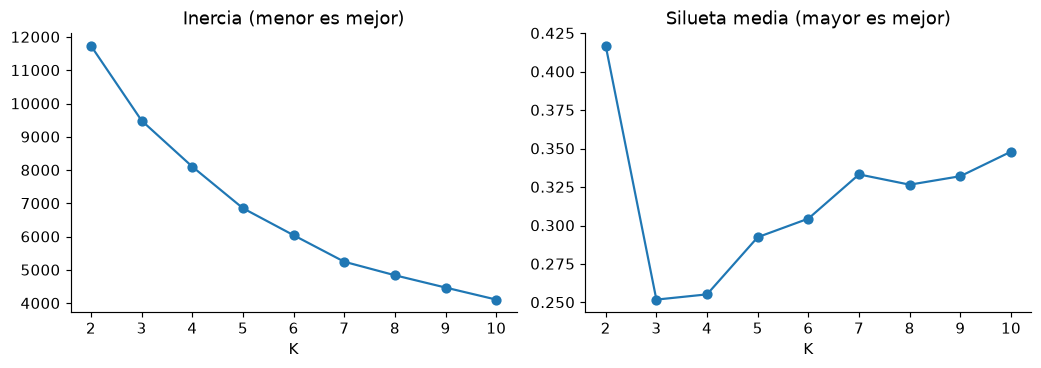

,K,inercia,silueta
0,2,11738.0113,0.4168
1,3,9489.4721,0.2519
2,4,8105.8745,0.2553
3,5,6856.2252,0.2924
4,6,6045.1941,0.3045
5,7,5248.6257,0.3333
6,8,4842.0831,0.3266
7,9,4472.4791,0.3321
8,10,4110.7465,0.3480


In [7]:
modelos1 = {K: km(X1, K) for K in range(2, 11)}
tabla1 = pd.DataFrame([{'K': K, 'inercia': modelo.inertia_, 'silueta': silhouette_score(X1, modelo.labels_)} for K, modelo in modelos1.items()])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, columna, titulo in zip(axes, ['inercia', 'silueta'], ['Inercia (menor es mejor)', 'Silueta media (mayor es mejor)']):
    ax.plot(tabla1.K, tabla1[columna], 'o-'); ax.set(xlabel='K', title=titulo); ax.set_xticks(tabla1.K)
plt.tight_layout(); plt.show()
tabla1.round(4)

**Respuesta:** La silueta media prefiere **K=2**, con 0.4168. La inercia disminuye al agregar grupos y el codo orientativo está alrededor de K=5: los descensos se hacen menores al seguir agregando grupos. Es una lectura de compromiso de la curva, no un mínimo que determine un K único. Para la cooperativa usaría K=5 como candidato operativo y lo contrastaría con los perfiles de (d), aunque no maximice la silueta. Más grupos siempre pueden reducir J; eso no demuestra que hagan falta más paquetes de asesoramiento.

### 1(b) Lo que elige la silueta

Para $K=2$, calcular el perfil de cada grupo —la media de cada feature en unidades originales— y listar los cultivos de las parcelas del grupo más chico. Explicar por qué la silueta media prefiere esa partición y si le sirve a la cooperativa.

In [8]:
etiquetas2 = modelos1[2].labels_
perfil2 = perfil(parcelas[ATRIB], etiquetas2)
grupo_chico = int(perfil2.n.idxmin())
cultivos_chico = pd.Series(cultivo[etiquetas2 == grupo_chico]).value_counts()
print('Perfil K=2:\n', perfil2.round(2).to_string())
print('Cultivos del grupo más chico:\n', cultivos_chico.to_string())

Perfil K=2:
        N       P       K  temperature  humidity    ph  rainfall     n
0  21.99  133.38  200.00        23.24     87.10  5.98     91.13   200
1  53.41   45.36   32.96        25.85     69.92  6.52    104.70  2000
Cultivos del grupo más chico:
 uva        100
manzana    100


**Respuesta:** El grupo pequeño tiene **200** parcelas: uva (100), manzana (100). Su P medio es 133.38 y K 200.00, muy por encima del otro grupo. Esa separación grande respecto del resto eleva la silueta, pero deja 2000 parcelas heterogéneas en un solo grupo. Distinguir el perfil extremo es útil; una partición de solo dos tipos no alcanza para organizar paquetes de fertilización y riego de toda la cooperativa.

### 1(c) La silueta y el escalado

Repetir el agrupamiento con $K=2$ **sin estandarizar**. Comparar la partición con la de (b) mediante el $\operatorname{ARI}$, y las dos siluetas medias. Explicar qué muestra el resultado sobre la comparación de siluetas medias calculadas con escalados distintos.

In [9]:
modelo1_crudo = km(X1_crudo, 2)
ari_crudo = adjusted_rand_score(etiquetas2, modelo1_crudo.labels_)
sil_estandar = silhouette_score(X1, etiquetas2)
sil_crudo = silhouette_score(X1_crudo, modelo1_crudo.labels_)
print(f'ARI entre particiones: {ari_crudo:.4f}')
print(f'Silueta en escala estandarizada: {sil_estandar:.4f}')
print(f'Silueta en escala original: {sil_crudo:.4f}')
print(pd.crosstab(etiquetas2, modelo1_crudo.labels_, rownames=['estandarizado'], colnames=['crudo']))

ARI entre particiones: 1.0000
Silueta en escala estandarizada: 0.4168
Silueta en escala original: 0.5451
crudo            0     1
estandarizado           
0              200     0
1                0  2000


**Respuesta:** ARI = **1.0000**; silueta estandarizada = **0.4168** y sin escalar = **0.5451**. El ARI indica cuánto cambia la pertenencia a grupos, independientemente del número que los identifica. Las siluetas se calculan con geometrías distintas: sin escalar pesan más los atributos con mayor dispersión numérica. Incluso si las etiquetas coinciden, la silueta puede cambiar. No se debe elegir el escalado por el valor más alto de silueta: las unidades y la relevancia agronómica deben justificar la distancia.

### 1(d) La estructura con más grupos

Para $K=3,4,5,6$, calcular el perfil de cada grupo y listar los cultivos que tienen al menos 50 de sus 100 parcelas en ese grupo. Describir cómo cambia la estructura al pasar de un $K$ al siguiente, nombrar los grupos de $K=5$ por los features que los distinguen y proponer un valor de $K$ para la cooperativa, justificado por el uso.


K=3:
       N       P       K  temperature  humidity    ph  rainfall     n                                                                                                                                            cultivos_al_menos_50
0  21.99  133.38  200.00        23.24     87.10  5.98     91.13   200                                                                                                                                        manzana (100), uva (100)
1  71.23   37.20   35.68        25.78     83.14  6.52    120.18  1213  algodón (100), arroz (100), banana (100), café (100), coco (100), granada (100), maíz (83), melón (100), naranja (100), papaya (100), sandía (100), yute (100)
2  25.95   57.95   28.79        25.97     49.55  6.52     80.83   787                             garbanzo (100), guandú (97), lenteja (100), mango (100), poroto moth (100), poroto mung (73), poroto negro (100), poroto rojo (100)

K=4:
       N       P       K  temperature  humidity    ph  rainfall    n

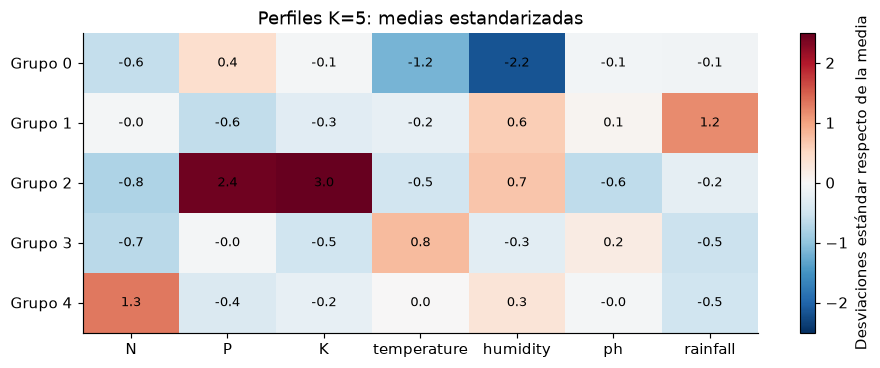

In [10]:
perfiles1, cruces_cultivos1 = {}, {}
for K in range(3, 7):
    etiquetas = modelos1[K].labels_
    tabla = perfil(parcelas[ATRIB], etiquetas)
    cruce = pd.crosstab(cultivo, etiquetas)
    tabla['cultivos_al_menos_50'] = [', '.join(f'{c} ({int(cruce.loc[c, g])})' for c in cruce.index if cruce.loc[c, g] >= 50) for g in tabla.index]
    perfiles1[K], cruces_cultivos1[K] = tabla, cruce
    print(f'\nK={K}:\n{tabla.round(2).to_string()}')
    if K > 3:
        print('Cruce con K anterior (los números de grupo son arbitrarios):')
        print(pd.crosstab(modelos1[K-1].labels_, etiquetas))
centros5 = pd.DataFrame(modelos1[5].cluster_centers_, columns=ATRIB)
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(centros5, cmap='RdBu_r', vmin=-2.5, vmax=2.5, aspect='auto')
ax.set_xticks(range(len(ATRIB)), ATRIB); ax.set_yticks(range(5), [f'Grupo {i}' for i in range(5)])
ax.set_title('Perfiles K=5: medias estandarizadas')
for i in range(5):
    for j in range(7):
        ax.text(j, i, f'{centros5.iloc[i,j]:.1f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='Desviaciones estándar respecto de la media')
plt.tight_layout(); plt.show()

**Respuesta:** Con K=3 se distinguen el perfil de P/K altos (200 parcelas), un conjunto de humedad alta (1213) y otro de menor humedad (787). Con K=4 se separa mejor el perfil de N alto del de precipitación alta. K=5 distingue un grupo especialmente seco y frío (236 parcelas) del resto más cálido. K=6 divide principalmente este último en un perfil de pH más bajo/humedad menor y otro de pH y humedad más altos, con pequeñas reasignaciones en otros grupos. Los cruces entre K consecutivos muestran que k-medias vuelve a optimizar todas las asignaciones: no es una jerarquía y los grupos pueden reorganizarse, no solamente subdividirse.

Para **K=5**, los perfiles se pueden nombrar así: grupo 0: humedad bajo/a (23.47), temperatura bajo/a (19.71), n=236; grupo 1: precipitación alto/a (168.12), P bajo/a (32.82), n=579; grupo 2: K alto/a (200.00), P alto/a (133.38), n=200; grupo 3: temperatura alto/a (29.57), N bajo/a (25.74), n=627; grupo 4: N alto/a (99.44), precipitación bajo/a (75.78), n=558.

Propondría **cinco tipos** para iniciar el servicio, porque distinguen combinaciones de nutrientes y clima que permiten diseñar recomendaciones diferentes sin multiplicar demasiado los paquetes. La tabla de cultivos con al menos 50 parcelas ayuda a darles contexto. No convertiría automáticamente una media de grupo en una dosis: validaría con técnicos y con la variación dentro de cada tipo. K=6 es una alternativa si su subdivisión justifica un paquete adicional.

### 1(e) Veintidós grupos contra veintidós cultivos

Ajustar k-medias con $K=22$ para cinco valores de `random_state`, de 0 a 4, y reportar el $\operatorname{ARI}$ contra el cultivo. Con la semilla 0, calcular para cada cultivo la fracción de sus parcelas que cae en su grupo más frecuente. Analizar los dos cultivos con la fracción más baja: qué feature los divide y qué supuesto de k-medias explica la división. Explicar por qué en este conjunto se puede calcular un $\operatorname{ARI}$ y si ese número responde la pregunta de la cooperativa.

In [11]:
modelos22 = {s: km(X1, 22, semilla=s) for s in range(5)}
ari22 = pd.DataFrame([{'semilla': s, 'ARI_cultivo': adjusted_rand_score(cultivo, modelo.labels_)} for s, modelo in modelos22.items()])
cruce22 = pd.crosstab(cultivo, modelos22[0].labels_)
fracciones22 = (cruce22.max(axis=1) / cruce22.sum(axis=1)).sort_values()
peores_cultivos = fracciones22.head(2).index.tolist()
perfiles_divididos, feature_divisora = {}, {}
for nombre in peores_cultivos:
    mask = cultivo == nombre
    etiquetas = modelos22[0].labels_[mask]
    tabla = perfil(parcelas.loc[mask, ATRIB], etiquetas)
    perfiles_divididos[nombre] = tabla
    promedios_z = pd.DataFrame(X1[mask], columns=ATRIB).groupby(etiquetas).mean()
    feature_divisora[nombre] = (promedios_z.max()-promedios_z.min()).idxmax()
    print(f'\n{nombre}:\n{tabla.round(2).to_string()}')
print('ARI por semilla:\n', ari22.round(4).to_string(index=False))
print('Fracción en el grupo más frecuente:\n', fracciones22.round(3).to_string())


uva:
        N       P       K  temperature  humidity    ph  rainfall   n
2   21.59  133.28  199.79        23.79     81.89  6.10     69.78  29
18  24.09  131.85  200.09        35.38     82.10  5.94     69.66  33
21  23.61  132.55  200.37        13.88     81.67  6.05     69.44  38

poroto moth:
        N      P      K  temperature  humidity    ph  rainfall   n
1   19.11  46.94  20.22        27.91     51.49  5.87     50.06  18
16  22.00  47.21  19.87        28.19     54.35  8.71     54.23  39
17  23.25  40.75  22.00        24.71     58.18  6.69     43.95   4
19  25.64  50.14  20.79        29.01     51.99  7.38     51.48  14
20  19.60  50.00  20.20        28.50     52.37  4.31     48.29  25
ARI por semilla:
  semilla  ARI_cultivo
       0       0.6709
       1       0.6611
       2       0.6282
       3       0.6519
       4       0.6695
Fracción en el grupo más frecuente:
 row_0
uva             0.38
poroto moth     0.39
guandú          0.48
papaya          0.53
naranja         0.60
lent

**Respuesta:** ARI contra cultivo por semilla: 0: 0.6709, 1: 0.6611, 2: 0.6282, 3: 0.6519, 4: 0.6695. Los casos menos concentrados son **uva**: fracción mayoritaria 38%; se divide principalmente por `temperature`, con medias por grupo entre 13.88 y 35.38; **poroto moth**: fracción mayoritaria 39%; se divide principalmente por `ph`, con medias por grupo entre 4.31 y 8.71.

K-medias minimiza distancias cuadradas y favorece grupos compactos, aproximadamente esféricos en la métrica elegida. Si un cultivo se extiende mucho a lo largo de temperatura o pH, puede reducir J partiéndolo y agrupando otros cultivos juntos; K=22 no obliga a recuperar los 22 nombres. El ARI se puede calcular porque existe una etiqueta externa, que no se usó para ajustar. Mide acuerdo con esa etiqueta, no utilidad para diseñar unos pocos tipos de asesoramiento.

### 1(f) El mapa de cultivos

Calcular el perfil promedio de cada cultivo, estandarizarlo con el **mismo** escalador de las parcelas y agrupar los 22 perfiles con el jerárquico aglomerativo y enlace de Ward. Dibujar el dendrograma, cortarlo en $K=3,\dots,6$ y comparar con lo obtenido en (d). Identificar tres cultivos que requieran condiciones parecidas y un par aislado del resto, y señalar qué información de las parcelas se pierde al agrupar perfiles.


K=3: {1: ['manzana', 'uva'], 2: ['garbanzo', 'guandú', 'lenteja', 'mango', 'poroto moth', 'poroto mung', 'poroto negro', 'poroto rojo'], 3: ['algodón', 'arroz', 'banana', 'café', 'coco', 'granada', 'maíz', 'melón', 'naranja', 'papaya', 'sandía', 'yute']}

K=4: {1: ['manzana', 'uva'], 2: ['garbanzo', 'guandú', 'lenteja', 'mango', 'poroto moth', 'poroto mung', 'poroto negro', 'poroto rojo'], 3: ['algodón', 'banana', 'maíz', 'melón', 'sandía'], 4: ['arroz', 'café', 'coco', 'granada', 'naranja', 'papaya', 'yute']}

K=5: {1: ['manzana', 'uva'], 2: ['garbanzo', 'poroto rojo'], 3: ['guandú', 'lenteja', 'mango', 'poroto moth', 'poroto mung', 'poroto negro'], 4: ['algodón', 'banana', 'maíz', 'melón', 'sandía'], 5: ['arroz', 'café', 'coco', 'granada', 'naranja', 'papaya', 'yute']}

K=6: {1: ['manzana', 'uva'], 2: ['garbanzo', 'poroto rojo'], 3: ['guandú', 'lenteja', 'mango', 'poroto moth', 'poroto mung', 'poroto negro'], 4: ['algodón', 'banana', 'maíz', 'melón', 'sandía'], 5: ['coco', 'granada'

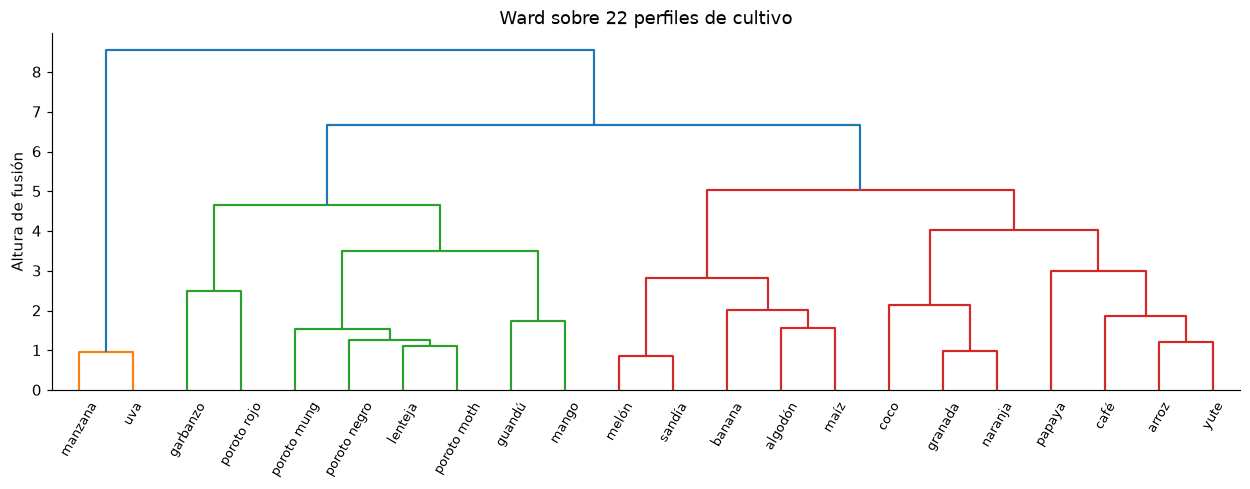

,K,ARI_Ward_perfiles_vs_kmedias_parcelas
0,3,0.9230
1,4,0.8458
2,5,0.7816
3,6,0.6343


In [12]:
from scipy.spatial.distance import pdist, squareform
from itertools import combinations

perfiles_cultivo = parcelas[ATRIB].groupby(cultivo).mean()
perfiles_cultivo_z = escalador1.transform(perfiles_cultivo)
Z_cultivos = linkage(perfiles_cultivo_z, method='ward')
fig, ax = plt.subplots(figsize=(12, 4.8))
dendrogram(Z_cultivos, labels=perfiles_cultivo.index.tolist(), leaf_rotation=60, leaf_font_size=9, ax=ax)
ax.set(title='Ward sobre 22 perfiles de cultivo', ylabel='Altura de fusión')
plt.tight_layout(); plt.show()
grupos_cultivos, comparacion_perfiles = {}, []
for K in range(3, 7):
    etiquetas = fcluster(Z_cultivos, K, criterion='maxclust')
    grupos_cultivos[K] = {int(g): perfiles_cultivo.index[etiquetas == g].tolist() for g in np.unique(etiquetas)}
    etiqueta_por_parcela = pd.Series(etiquetas, index=perfiles_cultivo.index).reindex(cultivo).to_numpy()
    comparacion_perfiles.append({'K': K, 'ARI_Ward_perfiles_vs_kmedias_parcelas': adjusted_rand_score(etiqueta_por_parcela, modelos1[K].labels_)})
    print(f'\nK={K}: {grupos_cultivos[K]}')
distancias_cultivos = squareform(pdist(perfiles_cultivo_z))
trio_indices = min(combinations(range(22), 3), key=lambda t: sum(distancias_cultivos[i,j] for i,j in combinations(t, 2)))
trio_cercano = perfiles_cultivo.index[list(trio_indices)].tolist()
print('Trío con menor suma de distancias entre perfiles:', trio_cercano)
pd.DataFrame(comparacion_perfiles).round(4)

**Respuesta:** El trío de perfiles con menor suma de distancias es **lenteja, poroto moth, poroto negro**; sus condiciones medias son parecidas en la escala de las parcelas. **Manzana y uva** forman el par aislado por sus niveles altos de P y K. El dendrograma y los cortes muestran qué otros perfiles se van separando entre K=3 y K=6.

La comparación con (d) se hizo llevando la etiqueta de cada cultivo a sus 100 parcelas antes de calcular el ARI: no se compararon directamente particiones de 22 y 2200 filas. El acuerdo disminuye de ARI=0,9230 en K=3 a 0,6343 en K=6: con más detalle pesan más las diferencias entre agrupar cultivos completos y parcelas individuales. Agrupar promedios conserva diferencias entre cultivos, pero pierde variación interna, solapamientos y subgrupos, como los rangos de temperatura de la uva y de pH del poroto moth. Todos tienen 100 parcelas en este conjunto; con tamaños distintos también habría que decidir cuánto ponderar cada perfil.

## 2. Estados y delitos

Un organismo federal quiere agrupar los estados de EE. UU. según su perfil delictivo para
diseñar programas de prevención distintos para cada grupo. Se trabaja sobre los 50 estados
en 1973, con la cantidad de arrestos por cada 100 000 habitantes por homicidio (`Murder`),
agresión (`Assault`) y violación (`Rape`), y el porcentaje de población urbana (`UrbanPop`).

Los cuatro features se **estandarizan**: `X2` es la matriz de todos los incisos.

In [13]:
X2 = StandardScaler().fit_transform(arrestos)

### 2(a) Cuatro enlaces

Agrupar con los cuatro enlaces —simple, completo, promedio y Ward—, dibujar los cuatro dendrogramas y reportar los tamaños de los grupos para $K=2,3,4$. Identificar los grupos de uno o dos estados y explicar el resultado del enlace simple a partir de su definición.

  enlace  K                     tamanos
  single  2               {1: 49, 2: 1}
  single  3         {1: 48, 2: 1, 3: 1}
  single  4   {1: 2, 2: 46, 3: 1, 4: 1}
complete  2              {1: 31, 2: 19}
complete  3        {1: 31, 2: 11, 3: 8}
complete  4 {1: 10, 2: 21, 3: 11, 4: 8}
 average  2              {1: 30, 2: 20}
 average  3        {1: 30, 2: 19, 3: 1}
 average  4  {1: 30, 2: 7, 3: 12, 4: 1}
    ward  2              {1: 19, 2: 31}
    ward  3       {1: 19, 2: 12, 3: 19}
    ward  4 {1: 7, 2: 12, 3: 12, 4: 19}
Grupos de uno o dos estados:
{'enlace': 'single', 'K': 2, 'grupo': 2, 'estados': ['Alaska']}
{'enlace': 'single', 'K': 3, 'grupo': 2, 'estados': ['Florida']}
{'enlace': 'single', 'K': 3, 'grupo': 3, 'estados': ['Alaska']}
{'enlace': 'single', 'K': 4, 'grupo': 1, 'estados': ['California', 'Nevada']}
{'enlace': 'single', 'K': 4, 'grupo': 3, 'estados': ['Florida']}
{'enlace': 'single', 'K': 4, 'grupo': 4, 'estados': ['Alaska']}
{'enlace': 'average', 'K': 3, 'grupo': 3, 'estados'

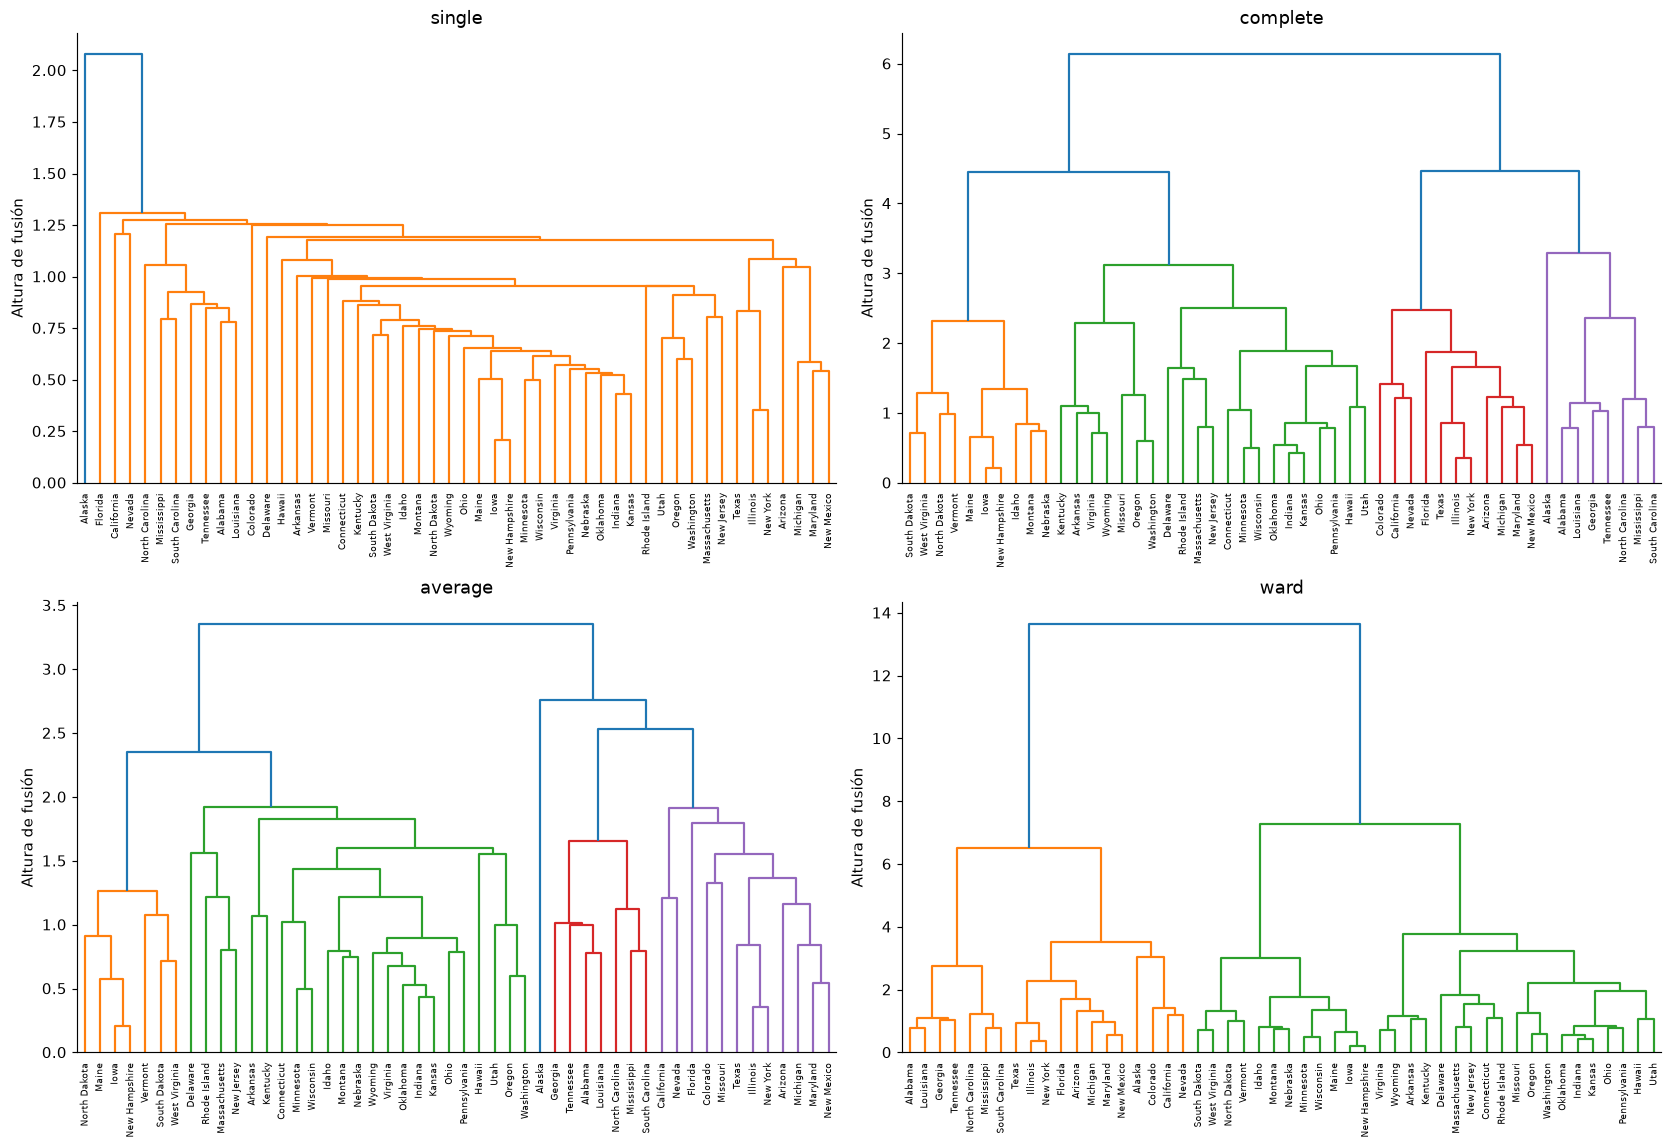

In [14]:
enlaces, resumen_enlaces, grupos_pequenos = {}, [], []
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, metodo in zip(axes.flat, ['single', 'complete', 'average', 'ward']):
    Z = linkage(X2, method=metodo)
    enlaces[metodo] = Z
    dendrogram(Z, labels=arrestos.index.tolist(), leaf_rotation=90, leaf_font_size=6, ax=ax)
    ax.set(title=metodo, ylabel='Altura de fusión')
    for K in [2, 3, 4]:
        etiquetas = fcluster(Z, K, criterion='maxclust')
        tamanos = pd.Series(etiquetas).value_counts().sort_index()
        resumen_enlaces.append({'enlace': metodo, 'K': K, 'tamanos': tamanos.to_dict()})
        for g, n in tamanos.items():
            if n <= 2:
                grupos_pequenos.append({'enlace': metodo, 'K': K, 'grupo': int(g), 'estados': arrestos.index[etiquetas == g].tolist()})
plt.tight_layout(); plt.show()
print(pd.DataFrame(resumen_enlaces).to_string(index=False))
print('Grupos de uno o dos estados:')
for grupo in grupos_pequenos:
    print(grupo)

**Respuesta:** Los grupos de uno o dos estados son: single, K=2: Alaska; single, K=3: Florida; single, K=3: Alaska; single, K=4: California, Nevada; single, K=4: Florida; single, K=4: Alaska; average, K=3: Alaska; average, K=4: Alaska. El enlace simple usa la menor distancia entre un punto de cada grupo. Una sucesión de vecinos cercanos puede unir perfiles bastante distintos por encadenamiento, dejando unos pocos estados aislados hasta el final. Completo controla la distancia máxima, promedio promedia pares y Ward elige la fusión con menor aumento de inercia; por eso sus tamaños y formas de agrupamiento difieren. Los estados aislados lo son en esta métrica y corte, no necesariamente los de mayor tasa en todos los delitos.

### 2(b) Ward: dos o cuatro grupos

Con el enlace de Ward, calcular la silueta media para $K=2,\dots,6$. Calcular los perfiles para $K=2$ y $K=4$ en unidades originales, describir cada grupo de $K=4$ y decidir cuál de los dos valores de $K$ le sirve al organismo.


Ward K=2:
   Murder  Assault  UrbanPop   Rape   n                                                                                                                                                                                                                                                                                                                           estados
1   12.33   259.32     68.32  29.22  19                                                                                                                            Alabama, Alaska, Arizona, California, Colorado, Florida, Georgia, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina, Tennessee, Texas
2    5.00   116.48     63.84  16.34  31  Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rh

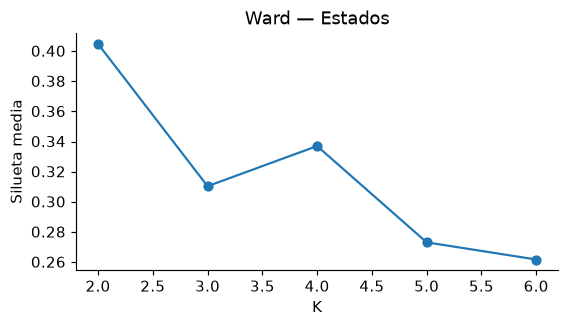

In [15]:
siluetas_ward2 = pd.DataFrame([{'K': K, 'silueta': silhouette_score(X2, fcluster(enlaces['ward'], K, criterion='maxclust'))} for K in range(2, 7)])
perfiles_ward2 = {}
for K in [2, 4]:
    etiquetas = fcluster(enlaces['ward'], K, criterion='maxclust')
    tabla = perfil(arrestos, etiquetas)
    tabla['estados'] = [', '.join(arrestos.index[etiquetas == g]) for g in tabla.index]
    perfiles_ward2[K] = tabla
    print(f'\nWard K={K}:\n{tabla.round(2).to_string()}')
print('Siluetas:\n', siluetas_ward2.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(siluetas_ward2.K, siluetas_ward2.silueta, 'o-'); ax.set(xlabel='K', ylabel='Silueta media', title='Ward — Estados')
plt.tight_layout(); plt.show()

**Respuesta:** La silueta máxima de Ward ocurre en **K=2**, con 0.4048. Con K=2 se obtiene una división general de perfiles, pero K=4 permite distinguir: **grupo 1**, homicidio alto y menor urbanización (Murder 14,67; UrbanPop 54,29%); **grupo 2**, agresión y violación altas, muy urbano (Assault 264; Rape 33,61; UrbanPop 76,50%); **grupo 3**, tasas bajas en los tres indicadores (Murder 3,09; Assault 76; Rape 11,83); **grupo 4**, niveles intermedios y urbanización alta (Murder 6,21; Assault 142,05; UrbanPop 71,26%).

Para un organismo que deba diseñar programas distintos, **K=4 es una segmentación operativa más detallada**. No demuestra la existencia de cuatro categorías naturales: es un corte útil que debe contrastarse con presupuesto, necesidades y resultados de intervención. Los indicadores son arrestos de 1973, no tasas actuales ni una medición completa de incidencia delictiva.

### 2(c) Ward y k-medias

Ajustar k-medias para $K=2,\dots,6$. Reportar el $\operatorname{ARI}$ con la partición de Ward del mismo $K$ y la inercia de cada una. A partir de la definición de $d_{\text{Ward}}$, explicar por qué las dos particiones se parecen, por qué la de k-medias tiene menor inercia y por qué el acuerdo baja al crecer $K$.

In [16]:
comparacion2 = []
for K in range(2, 7):
    kmeans = km(X2, K)
    ward = fcluster(enlaces['ward'], K, criterion='maxclust')
    comparacion2.append({'K': K, 'ARI': adjusted_rand_score(kmeans.labels_, ward), 'J_kmedias': kmeans.inertia_, 'J_Ward': inercia(X2, ward)})
comparacion2 = pd.DataFrame(comparacion2)
comparacion2.round(4)

,K,ARI,J_kmedias,J_Ward
0,2,0.9199,104.9616,106.7914
1,3,0.8284,80.0857,80.4291
2,4,0.8245,57.5543,59.1252
3,5,0.6845,50.0204,52.0111
4,6,0.5696,44.2524,45.7752


**Respuesta:** Los ARI para K=2–6 son 0.920, 0.828, 0.824, 0.685, 0.570. En estas corridas k-medias obtiene menor o igual J que Ward: True. Ambos se relacionan con la dispersión al centroide: Ward fusiona A y B por el incremento ΔJ = n_A·n_B/(n_A+n_B) · ||μ_A−μ_B||²; k-medias reasigna puntos y actualiza centroides para disminuir J a K fijo.

Ward toma decisiones de fusión irreversibles; k-medias puede mover observaciones entre grupos, aunque también puede terminar en óptimos locales. Por eso la menor inercia es un resultado observado aquí, no una garantía universal para cualquier inicialización. Con más grupos importan fronteras más finas y las fusiones previas restringen más a Ward, por lo que el acuerdo puede bajar; no tiene por qué caer de manera monótona.

### Antes del 2(d): qué controlan $\varepsilon$ y $m_{\text{pts}}$

DBSCAN llama **punto núcleo** a una observación que tiene al menos $m_{\text{pts}}$
observaciones —contándose a sí misma— a distancia $\le\varepsilon$. Los grupos son los
puntos núcleo conectados entre sí, más los puntos de **frontera** que caen en la vecindad de
alguno; el resto es **ruido**. Los dos hiperparámetros fijan juntos **la densidad mínima** que
se exige: $m_{\text{pts}}$ observaciones dentro de un radio $\varepsilon$.

- **$\varepsilon$ chico**: casi ninguna vecindad alcanza $m_{\text{pts}}$; los grupos se
  fragmentan y crece el ruido. **$\varepsilon$ grande**: las vecindades cruzan los huecos y
  los grupos se funden.
- **$m_{\text{pts}}$ chico**: basta poca densidad, y grupos de ruido pueden quedar como
  grupos. **$m_{\text{pts}}$ grande**: solo sobreviven las regiones muy densas.

Para verlo se usa un conjunto sintético en 2D, generado en el momento: dos lunas, un grupo
compacto, un grupo disperso y 50 puntos de ruido uniforme. La grilla siguiente ajusta DBSCAN
con tres valores de cada hiperparámetro; el ruido aparece en gris.

Resumen de la grilla: {(0.08, 4): {'grupos': 19, 'ruido': 130}, (0.15, 4): {'grupos': 4, 'ruido': 55}, (0.3, 4): {'grupos': 3, 'ruido': 33}, (0.08, 10): {'grupos': 11, 'ruido': 456}, (0.15, 10): {'grupos': 4, 'ruido': 82}, (0.3, 10): {'grupos': 3, 'ruido': 34}, (0.08, 30): {'grupos': 1, 'ruido': 588}, (0.15, 30): {'grupos': 1, 'ruido': 570}, (0.3, 30): {'grupos': 4, 'ruido': 54}}


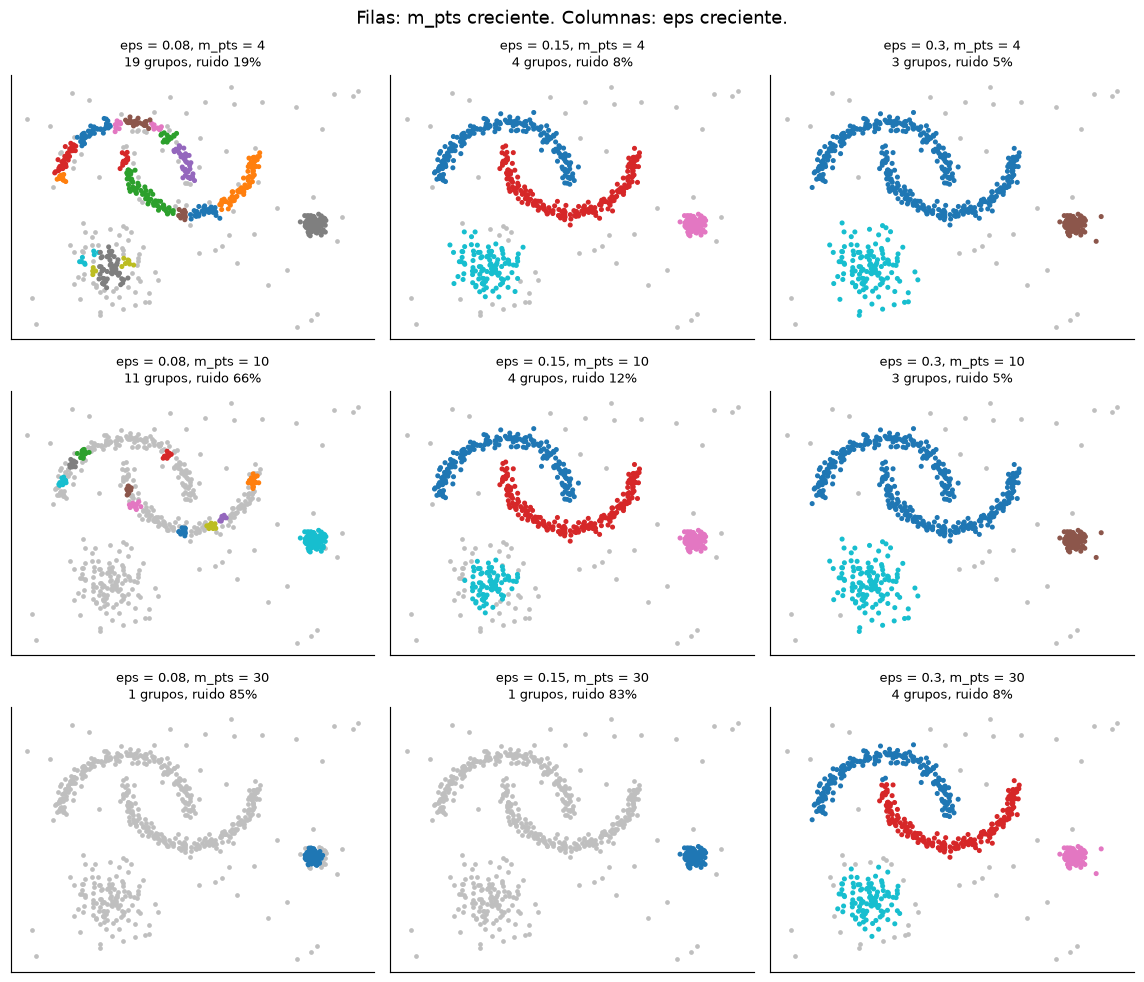

In [17]:
from sklearn.datasets import make_blobs, make_moons

rng = np.random.default_rng(SEMILLA)
lunas, _ = make_moons(n_samples=400, noise=0.06, random_state=SEMILLA)
compacto, _ = make_blobs(n_samples=120, centers=[[2.9, -0.7]], cluster_std=0.08,
                         random_state=SEMILLA)
disperso, _ = make_blobs(n_samples=120, centers=[[-0.3, -1.4]], cluster_std=0.3,
                         random_state=SEMILLA + 1)
ruido_uniforme = rng.uniform([-1.6, -2.4], [3.6, 1.6], size=(50, 2))
X_dbscan = np.vstack([lunas, compacto, disperso, ruido_uniforme])


def dibujar_dbscan(X: np.ndarray, eps: float, m_pts: int, ax=None) -> np.ndarray:
    """Ajusta DBSCAN y dibuja los grupos en color y el ruido en gris. Devuelve las etiquetas."""
    etiquetas = DBSCAN(eps=eps, min_samples=m_pts).fit_predict(X)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 3.8))
    ax.scatter(X[etiquetas == -1, 0], X[etiquetas == -1, 1], s=5, c="0.75")
    ax.scatter(X[etiquetas >= 0, 0], X[etiquetas >= 0, 1], s=6,
               c=etiquetas[etiquetas >= 0], cmap="tab10")
    ax.set_title(f"eps = {eps}, m_pts = {m_pts}\n{etiquetas.max() + 1} grupos, "
                 f"ruido {np.mean(etiquetas == -1):.0%}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    return etiquetas


fig, ejes = plt.subplots(3, 3, figsize=(11, 9.5))
for i, m_pts in enumerate((4, 10, 30)):
    for j, eps in enumerate((0.08, 0.15, 0.3)):
        dibujar_dbscan(X_dbscan, eps, m_pts, ax=ejes[i, j])
fig.suptitle("Filas: m_pts creciente. Columnas: eps creciente.")
fig.tight_layout()
plt.show()

grid_dbscan = {}
for m in [4, 10, 30]:
    for eps in [.08, .15, .3]:
        y = DBSCAN(eps=eps, min_samples=m).fit_predict(X_dbscan)
        grid_dbscan[(eps, m)] = {'grupos': len(set(y)-{-1}), 'ruido': int((y == -1).sum())}
print('Resumen de la grilla:', grid_dbscan)


La celda siguiente permite mover los dos hiperparámetros con controles deslizantes. En
Colab funciona sin instalar nada; si `ipywidgets` no está disponible, se usa
`dibujar_dbscan(X_dbscan, eps, m_pts)` con los valores a mano.

interactive(children=(FloatSlider(value=0.15, description='eps', max=0.6, min=0.03, step=0.01), IntSlider(value=10, description='m_pts', max=60, min=2), Output()), _dom_classes=('widget-interact',))


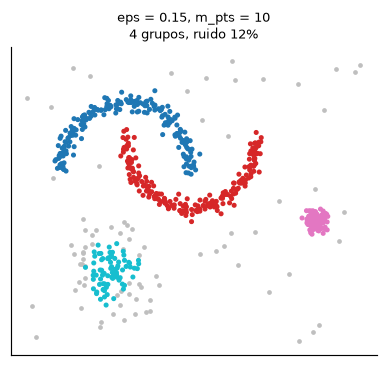

In [18]:
try:
    from ipywidgets import FloatSlider, IntSlider, interact

    def _explorar(eps: float = 0.15, m_pts: int = 10) -> None:
        dibujar_dbscan(X_dbscan, eps, m_pts)
        plt.show()

    interact(_explorar,
             eps=FloatSlider(value=0.15, min=0.03, max=0.6, step=0.01),
             m_pts=IntSlider(value=10, min=2, max=60))
except ImportError:
    print("ipywidgets no está instalado: usar dibujar_dbscan(X_dbscan, eps, m_pts).")

### Para analizar

1. Con $m_{\text{pts}}$ fijo, ¿qué les pasa a las lunas al pasar de $\varepsilon=0{,}08$ a
   $0{,}3$? Con $\varepsilon$ fijo, ¿qué grupo desaparece primero al subir $m_{\text{pts}}$, y
   por qué ese?
2. ¿Por qué con $\varepsilon=0{,}3$ y $m_{\text{pts}}=30$ se recuperan los cuatro grupos, si con
   $\varepsilon=0{,}3$ y $m_{\text{pts}}=4$ no?

**Respuesta:**

1. Al aumentar ε crecen las vecindades: las lunas pasan de fragmentos/ruido a componentes conectadas, pero radios grandes también pueden unirlas mediante puentes. A ε fijo, subir m_pts exige más densidad; el grupo disperso deja de sostener suficientes núcleos antes que el compacto. Los puntos de ruido uniforme tampoco suelen sostener un grupo estable.
2. Con ε=0,3 y m_pts=4 se obtienen 3 grupos y 33 puntos de ruido; con m_pts=30, 4 y 54. Exigir 30 vecinos elimina núcleos de baja densidad que con 4 podían formar puentes entre estructuras; las cuatro regiones suficientemente densas siguen teniendo núcleos. Más exigencia no equivale simplemente a “menos grupos”: también puede romper conexiones artificiales.

### Elegir $\varepsilon$ con el gráfico de k-distancias

La regla práctica: fijar $m_{\text{pts}}$, graficar la distancia de cada observación a su
$m_{\text{pts}}$-ésima más cercana en orden decreciente, y tomar $\varepsilon$ en el **codo**,
donde la curva pasa de los puntos aislados —distancias grandes— a los de las regiones
densas.

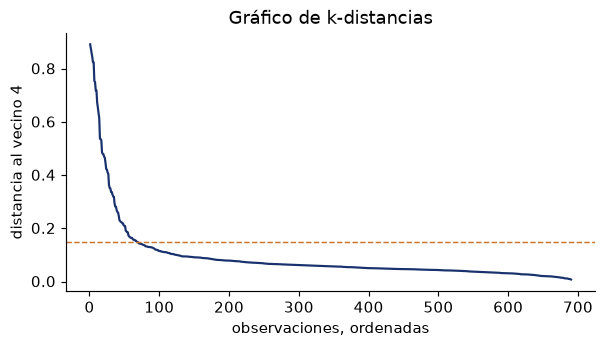

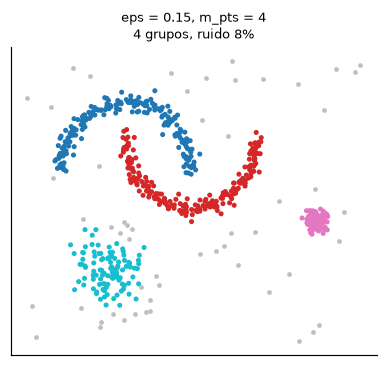

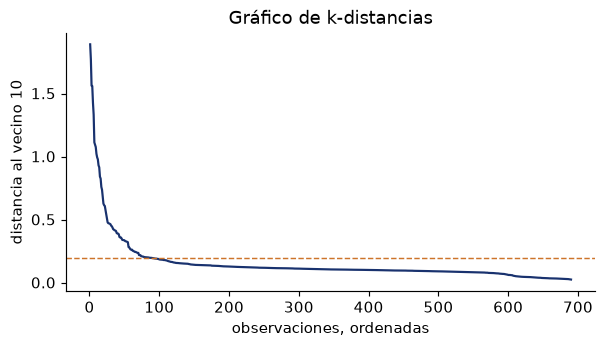

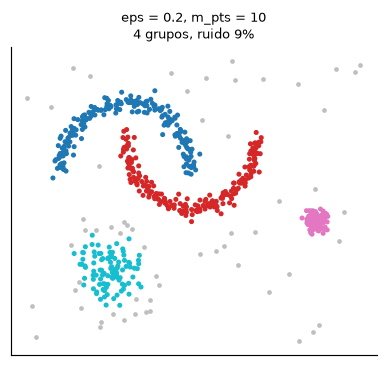

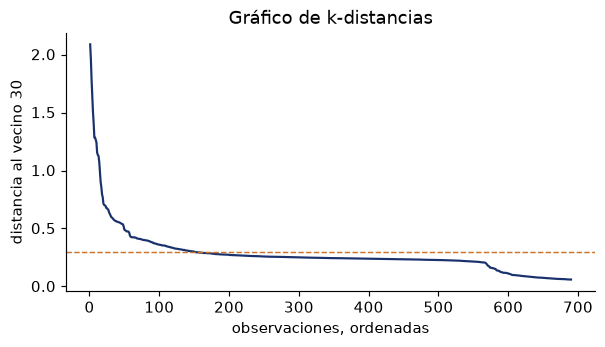

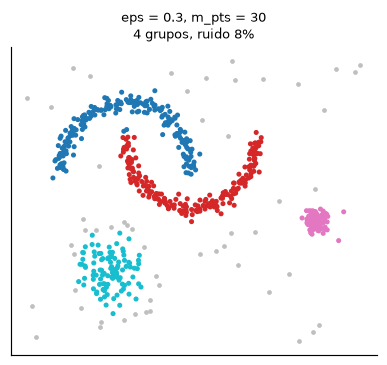

,m_pts,eps,mediana_distancia,p90_distancia,grupos,ruido
0,4,0.15,0.057,0.147,4,55
1,10,0.20,0.106,0.237,4,59
2,30,0.30,0.244,0.412,4,54


In [19]:
eps_elegidos = {4: .15, 10: .20, 30: .30}
resumen_codos = []
for m_pts, eps in eps_elegidos.items():
    distancias = graficar_k_distancias(X_dbscan, m_pts, eps=(eps,))
    etiquetas = dibujar_dbscan(X_dbscan, eps, m_pts)
    plt.show()
    resumen_codos.append({'m_pts': m_pts, 'eps': eps, 'mediana_distancia': np.median(distancias), 'p90_distancia': np.quantile(distancias, .9),
        'grupos': len(set(etiquetas)-{-1}), 'ruido': int((etiquetas == -1).sum())})
pd.DataFrame(resumen_codos).round(3)

### Para analizar

¿Cómo cambia la posición del codo al subir $m_{\text{pts}}$? ¿Hay un único par
$(\varepsilon, m_{\text{pts}})$ correcto?

**Respuesta:** Al subir m_pts la distancia al vecino de ese orden no puede disminuir, por lo que el radio candidato tiende a aumentar. Se probaron ε=0,15, 0,20 y 0,30 para m_pts=4, 10 y 30, y se mostraron sus curvas y particiones. Son elecciones visuales orientativas, no resultados de una regla infalible: las densidades distintas pueden generar varios cambios de pendiente. No existe un único par correcto sin definir qué estructuras se quieren recuperar y cuánto ruido se acepta; se revisa la estabilidad ante pequeños cambios de ambos parámetros.

### 2(d) DBSCAN

Graficar las k-distancias con $m_{\text{pts}}=5$ y ajustar DBSCAN con $\varepsilon$ igual a $0{,}8$, $1{,}0$, $1{,}2$, $1{,}3$, $1{,}4$, $1{,}6$ y $2{,}0$, reportando la cantidad de grupos, sus tamaños y los estados marcados como ruido. Explicar qué dice el resultado sobre la estructura de densidad de los datos y cómo se compatibiliza con lo obtenido en (b).

 eps  grupos       tamanos  n_ruido                                                                                                                                                                                                                                                                                                                                                  estados_ruido
 0.8       2 {0: 11, 1: 6}       33 Alabama, Alaska, Arizona, Arkansas, California, Colorado, Connecticut, Delaware, Florida, Georgia, Hawaii, Illinois, Kentucky, Louisiana, Maryland, Massachusetts, Michigan, Mississippi, Missouri, Nevada, New Jersey, New Mexico, New York, North Carolina, Oregon, Rhode Island, South Carolina, Tennessee, Texas, Utah, Vermont, Washington, West Virginia
 1.0       2 {0: 24, 1: 3}       23                                                                                                                    Alabama, Alaska, Arizona, Arkansas, California, Colorado, Delaware, Florida

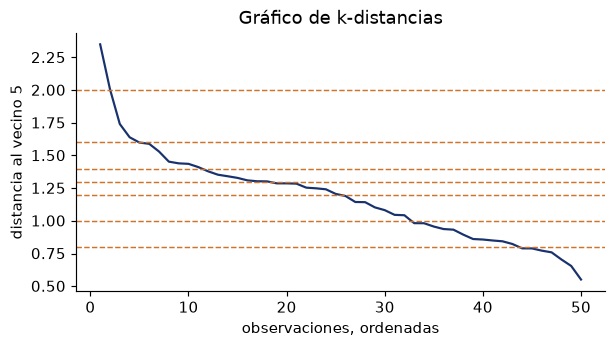

In [20]:
eps_estados = [.8, 1., 1.2, 1.3, 1.4, 1.6, 2.]
distancias_estados = graficar_k_distancias(X2, 5, eps=tuple(eps_estados))
dbscan_estados = []
for eps in eps_estados:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X2)
    grupos = sorted(set(etiquetas)-{-1})
    dbscan_estados.append({'eps': eps, 'grupos': len(grupos), 'tamanos': {int(g): int((etiquetas == g).sum()) for g in grupos},
        'n_ruido': int((etiquetas == -1).sum()), 'estados_ruido': ', '.join(arrestos.index[etiquetas == -1])})
tabla_dbscan_estados = pd.DataFrame(dbscan_estados)
print(tabla_dbscan_estados.to_string(index=False))

**Respuesta:** ε=0.8: 2 grupos/33 ruido, ε=1: 2 grupos/23 ruido, ε=1.2: 2 grupos/13 ruido, ε=1.3: 1 grupos/4 ruido, ε=1.4: 1 grupos/1 ruido, ε=1.6: 1 grupos/1 ruido, ε=2: 1 grupos/1 ruido. No aparece una partición estable de cuatro regiones densas que persista al variar el radio: con radios exigentes se descartan muchos estados o aparecen pequeños componentes, y al relajarlos se conectan grandes partes del conjunto. Eso sugiere un continuo de perfiles con densidad variable, no cuatro islas bien separadas. Es compatible con Ward K=4: Ward siempre permite cortar una jerarquía y resumir diferencias útiles, aun cuando no haya huecos de densidad. “Ruido” depende de ε, m_pts y el escalado; no es una categoría delictiva ni significa dato incorrecto.

### 2(e) El informe

El informe preliminar del organismo concluye: «Los estados se dividen naturalmente en cuatro tipos delictivos, y cada uno recibirá un programa de prevención propio.» Con los resultados de (a) a (d), indicar qué parte de la afirmación está respaldada, cuál no, y qué habría que verificar antes de asignar recursos según esos grupos.

**Respuesta:** Está respaldado que se puede construir una segmentación de cuatro perfiles diferentes para organizar programas. No está respaldado llamarlos cuatro tipos “naturales”: los enlaces no coinciden exactamente, el corte de Ward requiere una decisión del analista y DBSCAN no confirma cuatro componentes de densidad estables.

Antes de asignar recursos verificaría estabilidad ante variables, pesos, escalado y pequeñas perturbaciones; dispersión dentro de cada grupo; calidad y comparabilidad de los registros; y necesidades y resultados de programas. Hay que actualizar datos de 1973 y distinguir arrestos de incidencia: diferencias de registro y actuación institucional pueden influir. La asignación requiere objetivos, costos y una evaluación de impacto, no solamente el número de grupo.

## 3. Clientes de una agencia de viajes

Una agencia de viajes quiere segmentar a sus clientes para diseñar campañas comerciales
distintas, entre ellas la oferta de un seguro de viaje. Dispone de 1987 clientes con tres
features numéricos —edad en años (`edad`), ingreso anual en rupias (`ingreso`) y cantidad de
integrantes de la familia (`familia`)— y cinco binarios: sector de empleo (`privado`),
título universitario (`titulo`), enfermedad crónica (`cronica`), viajero frecuente
(`frecuente`) y si viajó alguna vez al exterior (`exterior`). Los binarios ya están
codificados con $1$ para sector privado y para cada «sí». El vector `compra` indica si el
cliente compró el seguro: **no entra al agrupamiento**, y se usa solo en el inciso (d).

Se trabaja sobre los ocho features **estandarizados**: `X3` es la matriz de los incisos (a)
a (d).

In [21]:
X3 = StandardScaler().fit_transform(clientes)

### 3(a) k-medias

Ajustar k-medias para $K=2,\dots,8$ y reportar la inercia y la silueta media. Para $K=3$, calcular el perfil de cada grupo en unidades originales, nombrar cada grupo e indicar qué features lo definen.

 K    inercia  silueta
 2 13089.7743   0.2365
 3 11232.7112   0.2034
 4  9733.9986   0.2268
 5  8825.5889   0.2276
 6  8146.8655   0.2224
 7  7726.9213   0.1885
 8  7140.2600   0.2263
Perfil K=3:
      edad      ingreso  familia  privado  titulo  cronica  frecuente  exterior     n
0  29.589   880048.309    4.781    1.000   0.814    0.267      0.150     0.000  1035
1  29.081  1381527.094    4.670    0.941   0.857    0.293      0.530     0.884   406
2  30.189   698992.674    4.762    0.000   0.919    0.288      0.086     0.038   546


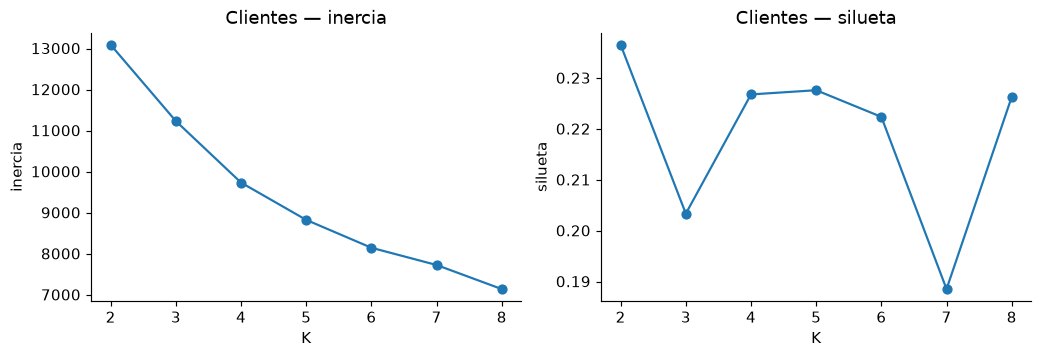

In [22]:
modelos3 = {K: km(X3, K) for K in range(2, 9)}
tabla3 = pd.DataFrame([{'K': K, 'inercia': modelo.inertia_, 'silueta': silhouette_score(X3, modelo.labels_)} for K, modelo in modelos3.items()])
kmedias3 = modelos3[3].labels_
perfil_kmedias3 = perfil(clientes, kmedias3)
print(tabla3.round(4).to_string(index=False))
print('Perfil K=3:\n', perfil_kmedias3.round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ['inercia', 'silueta']):
    ax.plot(tabla3.K, tabla3[name], 'o-'); ax.set(xlabel='K', ylabel=name, title='Clientes — ' + name)
plt.tight_layout(); plt.show()

**Respuesta:** La silueta mayor entre K=2–8 corresponde a K=2, con 0.2365; la inercia se reduce al aumentar K y no fija por sí sola una solución comercial.

En K=3: **grupo 0, privados sin viaje al exterior**, n=1035, privado 100.0%, exterior 0.0%; **grupo 1, ingreso alto y experiencia internacional**, n=406, ingreso medio 1,381,527, exterior 88.4%; **grupo 2, empleo público y menor ingreso**, n=546, privado 0.0%, ingreso 698,993. Edad y tamaño familiar cambian poco; la separación principal pasa por empleo, exterior e ingreso. Los promedios de binarios son proporciones, no valores intermedios de una categoría.

### 3(b) Ward

Agrupar los mismos datos con el jerárquico aglomerativo y enlace de Ward, y cortar en $K=3$. Calcular los perfiles, el $\operatorname{ARI}$ con la partición de (a), su tabla cruzada, la inercia y la silueta media de las dos particiones. Explicar por qué dos procedimientos que buscan reducir la misma función de costo cortan por features distintos, y por qué la de mayor inercia puede tener mayor silueta media.

In [23]:
Z_clientes = linkage(X3, method='ward')
ward3 = fcluster(Z_clientes, 3, criterion='maxclust')
perfil_ward3 = perfil(clientes, ward3)
ari_metodos3 = adjusted_rand_score(kmedias3, ward3)
cruce_metodos3 = pd.crosstab(kmedias3, ward3, rownames=['k-medias'], colnames=['Ward'])
metricas_metodos3 = pd.DataFrame([{'metodo': nombre, 'inercia': inercia(X3, etiquetas), 'silueta': silhouette_score(X3, etiquetas)} for nombre, etiquetas in [('k-medias', kmedias3), ('Ward', ward3)]])
print('Perfil Ward:\n', perfil_ward3.round(3).to_string())
print(f'ARI: {ari_metodos3:.4f}')
print('Cruce:\n', cruce_metodos3.to_string())
metricas_metodos3.round(4)

Perfil Ward:
      edad      ingreso  familia  privado  titulo  cronica  frecuente  exterior     n
1  29.232  1349316.940    4.653    0.877     1.0    0.284      0.478     0.932   366
2  29.461   835254.237    4.671    0.851     0.0    0.258      0.237     0.132   295
3  29.808   839479.638    4.799    0.637     1.0    0.281      0.130     0.000  1326
ARI: 0.3370
Cruce:
 Ward        1    2    3
k-medias               
0           0  193  842
1         345   58    3
2          21   44  481


,metodo,inercia,silueta
0,k-medias,11232.7112,0.2034
1,Ward,11402.0403,0.2547


**Respuesta:** ARI k-medias/Ward = **0.3370**. K-medias: J=11232.71, silueta=0.2034; Ward: J=11402.04, silueta=0.2547. Ward separa un grupo de ingreso alto, graduados y viaje al exterior; otro de no graduados (`titulo=0`); y otro de graduados sin exterior. En cambio, k-medias separa con fuerza el sector de empleo entre quienes no están en el grupo internacional.

Los dos reducen dispersión, pero por procedimientos distintos y con restricciones de trayectoria distintas: Ward no deshace fusiones. La silueta combina distancias a miembros del propio grupo y al grupo vecino; no es la inercia ni una transformación monótona de ella. Por eso la partición de mayor J puede obtener mayor silueta.

### 3(c) DBSCAN

Graficar las k-distancias con $m_{\text{pts}}=30$ y ajustar DBSCAN con $\varepsilon$ igual a $1{,}0$, $1{,}5$, $2{,}0$, $2{,}5$ y $3{,}0$, reportando la cantidad de grupos, sus tamaños y la cantidad de clientes marcados como ruido. Con $\varepsilon=1{,}5$, verificar qué tienen en común los clientes de cada grupo. Con $\varepsilon=2{,}5$, calcular los perfiles y el $\operatorname{ARI}$ con las particiones de (a) y (b). Para explicar los resultados, tener en cuenta que un feature binario estandarizado toma solo dos valores, y calcular la distancia entre ellos para cada uno de los cinco binarios.

 eps  grupos                                                                       tamanos  ruido
 1.0       8                   {0: 150, 1: 37, 2: 496, 3: 278, 4: 33, 5: 88, 6: 67, 7: 47}    791
 1.5       8                 {0: 122, 1: 514, 2: 203, 3: 306, 4: 89, 5: 92, 6: 113, 7: 91}    457
 2.0      10 {0: 128, 1: 514, 2: 206, 3: 124, 4: 306, 5: 95, 6: 111, 7: 116, 8: 32, 9: 47}    308
 2.5       3                                                     {0: 1351, 1: 249, 2: 334}     53
 3.0       1                                                                     {0: 1987}      0
Combinaciones binarias por grupo (eps=1.5):
{'grupo': 0, 'n': 122, 'n_combinaciones_binarias': 1, 'combinaciones': [{'privado': 0, 'titulo': 1, 'cronica': 1, 'frecuente': 0, 'exterior': 0}]}
{'grupo': 1, 'n': 514, 'n_combinaciones_binarias': 1, 'combinaciones': [{'privado': 1, 'titulo': 1, 'cronica': 0, 'frecuente': 0, 'exterior': 0}]}
{'grupo': 2, 'n': 203, 'n_combinaciones_binarias': 1, 'combinaciones': [{'

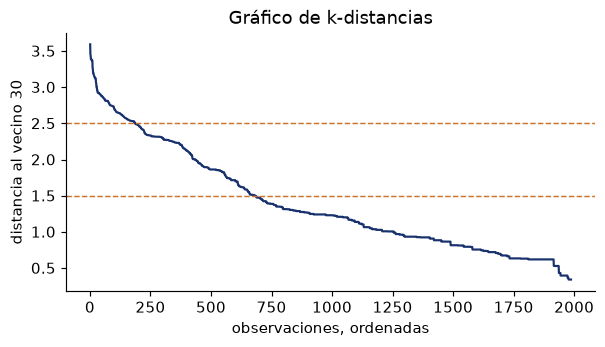

,proporcion_1,distancia_0_a_1_estandarizada
privado,0.7131,2.2109
titulo,0.8515,2.8125
cronica,0.2778,2.2326
frecuente,0.2099,2.4557
exterior,0.1912,2.5427


In [24]:
graficar_k_distancias(X3, 30, eps=(1.5, 2.5))
etiquetas_dbscan3, resumen_dbscan3 = {}, []
for eps in [1., 1.5, 2., 2.5, 3.]:
    etiquetas = DBSCAN(eps=eps, min_samples=30).fit_predict(X3)
    etiquetas_dbscan3[eps] = etiquetas
    grupos = sorted(set(etiquetas)-{-1})
    resumen_dbscan3.append({'eps': eps, 'grupos': len(grupos), 'tamanos': {int(g): int((etiquetas == g).sum()) for g in grupos}, 'ruido': int((etiquetas == -1).sum())})
print(pd.DataFrame(resumen_dbscan3).to_string(index=False))
patrones15 = []
for g in sorted(set(etiquetas_dbscan3[1.5])-{-1}):
    mask = etiquetas_dbscan3[1.5] == g
    patrones = clientes.loc[mask, BINARIOS].drop_duplicates()
    patrones15.append({'grupo': int(g), 'n': int(mask.sum()), 'n_combinaciones_binarias': len(patrones), 'combinaciones': patrones.to_dict('records')})
print('Combinaciones binarias por grupo (eps=1.5):')
for row in patrones15:
    print(row)
perfil_db25 = perfil(clientes, etiquetas_dbscan3[2.5])
ari_db25_km = adjusted_rand_score(etiquetas_dbscan3[2.5], kmedias3)
ari_db25_ward = adjusted_rand_score(etiquetas_dbscan3[2.5], ward3)
frecuencias_binarias = clientes[BINARIOS].mean()
saltos_binarios = 1 / np.sqrt(frecuencias_binarias * (1-frecuencias_binarias))
print('Perfil eps=2.5 (−1 sería ruido):\n', perfil_db25.round(3).to_string())
print(f'ARI DBSCAN vs k-medias: {ari_db25_km:.4f}; vs Ward: {ari_db25_ward:.4f}')
pd.DataFrame({'proporcion_1': frecuencias_binarias, 'distancia_0_a_1_estandarizada': saltos_binarios}).round(4)

**Respuesta:** ε=1: 8 grupos, 791 ruido; ε=1.5: 8 grupos, 457 ruido; ε=2: 10 grupos, 308 ruido; ε=2.5: 3 grupos, 53 ruido; ε=3: 1 grupos, 0 ruido. Con ε=1,5, todos los grupos no ruido tienen una sola combinación de los cinco binarios: **True**; la tabla muestra esas combinaciones. Para un binario de proporción p, StandardScaler genera un salto de **1/√(p(1−p))**, al menos 2. Aquí los saltos son privado=2.211, titulo=2.812, cronica=2.233, frecuente=2.456, exterior=2.543; un solo cambio binario ya impide ser vecinos a radio 1,5.

Con ε=2,5, el ARI es **0.3085** con k-medias y **0.9434** con Ward. A radio 2,5 todavía no se pueden cruzar los saltos de `titulo` y `exterior`, y los grupos principales corresponden a graduados sin exterior, no graduados sin exterior y graduados con exterior; quedan 53 clientes como ruido. Eso explica el parecido con Ward (ARI=0,9434), que también separa por esos atributos. Los ARI reportados incluyen −1 como una etiqueta adicional: no se interpreta el ruido como un segmento comercial. Los otros saltos pueden cruzarse si también alcanza el radio para las diferencias numéricas. Buena parte de la estructura de densidad refleja combinaciones de categorías impuestas por la codificación y su ponderación. No demuestra segmentos comerciales naturales. Las filas repetidas, conservadas porque no hay ID para decidir si son duplicados reales, también aumentan la densidad observada.

### 3(d) La compra del seguro

Calcular la tasa de compra del seguro en cada grupo de k-medias con $K=2,3,4$ y de Ward con $K=3$, y compararla con la tasa global y con la tasa según `exterior` y según el cuartil de ingreso. Indicar qué partición le sirve a la agencia para la campaña del seguro y por qué. Si el objetivo fuera solo decidir a quién ofrecerle el seguro, discutir si corresponde agrupar.

In [25]:
tasa_global = float(compra.mean())
tasas_particiones = []
for nombre, etiquetas in [('k-medias K=2', modelos3[2].labels_), ('k-medias K=3', kmedias3), ('k-medias K=4', modelos3[4].labels_), ('Ward K=3', ward3)]:
    tabla = perfil(clientes, etiquetas)
    tabla['tasa_compra'] = pd.Series(compra).groupby(etiquetas).mean()
    print(f'\n{nombre}:\n{tabla.round(3).to_string()}')
    for grupo, row in tabla.iterrows():
        tasas_particiones.append({'particion': nombre, 'grupo': int(grupo), 'n': int(row.n), 'tasa': row.tasa_compra})
tasas_particiones = pd.DataFrame(tasas_particiones)
tasas_exterior = pd.DataFrame({'compra': compra, 'exterior': clientes.exterior}).groupby('exterior').compra.agg(['mean', 'size'])
cuartiles = pd.qcut(clientes.ingreso, 4, labels=False)
tasas_cuartiles = pd.DataFrame({'compra': compra, 'cuartil': cuartiles}).groupby('cuartil').compra.agg(['mean', 'size'])
print(f'Tasa global: {tasa_global:.4f}')
print('Según exterior:\n', tasas_exterior.round(4).to_string())
print('Según cuartil de ingreso (0=menor):\n', tasas_cuartiles.round(4).to_string())


k-medias K=2:
     edad      ingreso  familia  privado  titulo  cronica  frecuente  exterior     n  tasa_compra
0  29.027  1346421.053    4.663    0.926   0.859    0.293      0.571     0.779   475        0.728
1  29.846   802810.847    4.781    0.646   0.849    0.273      0.097     0.007  1512        0.241

k-medias K=3:
     edad      ingreso  familia  privado  titulo  cronica  frecuente  exterior     n  tasa_compra
0  29.589   880048.309    4.781    1.000   0.814    0.267      0.150     0.000  1035        0.246
1  29.081  1381527.094    4.670    0.941   0.857    0.293      0.530     0.884   406        0.823
2  30.189   698992.674    4.762    0.000   0.919    0.288      0.086     0.038   546        0.222

k-medias K=4:
     edad      ingreso  familia  privado  titulo  cronica  frecuente  exterior    n  tasa_compra
0  29.193  1390771.350    4.689    0.934   0.959    0.295      0.532     0.923  363        0.840
1  30.161   727788.845    4.789    0.000   1.000    0.281      0.094     0.

**Respuesta:** La tasa global es **35.7%**. En k-medias K=3 va de 22.2% a 82.3%; en Ward K=3 de 23.7% a 81.1%. Según exterior, las tasas son 25.6% sin experiencia internacional y 78.4% con ella. Del menor al mayor cuartil de ingreso: 18.7%, 26.4%, 24.6%, 80.2%.

Si se necesita una segmentación para campañas diferenciadas, **k-medias K=2 es un punto de partida simple**: separa 475 clientes con 72,8% de compra observada de 1512 con 24,1%, sin multiplicar campañas. Para una campaña más focalizada, el grupo internacional de K=3 ofrece 82,3% sobre 406 clientes; el presupuesto y la cobertura buscada decidirían si compensa ese recorte. K=3/4 o Ward K=3 solo se justificarían si sus subgrupos permiten mensajes o acciones diferentes; separar por empleo o título no garantiza una mejora de conversión. Las tasas y tamaños impresos permiten evaluar esa decisión y compararla con reglas simples de exterior/ingreso.

Si el único objetivo es estimar quién comprará, ya existe una respuesta observada y conviene un modelo supervisado con validación fuera de muestra y criterio de costo/beneficio. Estos porcentajes describen esta muestra; no miden el efecto causal de ofrecer el seguro. Para medir el beneficio incremental de una campaña haría falta un experimento o diseño causal apropiado.

### 3(e) Otro escalado

Repetir k-medias con $K=3$ dejando los binarios en $0$ y $1$ y estandarizando solo los tres features numéricos. Calcular los perfiles y el $\operatorname{ARI}$ con la partición de (a). Explicar qué muestra el resultado sobre la elección del escalado cuando hay features numéricos y binarios.

In [26]:
X3_01 = np.hstack([StandardScaler().fit_transform(clientes[NUMERICOS]), clientes[BINARIOS].to_numpy(float)])
modelo3_01 = km(X3_01, 3)
kmedias3_01 = modelo3_01.labels_
perfil_01 = perfil(clientes, kmedias3_01)
perfil_01['tasa_compra'] = pd.Series(compra).groupby(kmedias3_01).mean()
ari_escalado3 = adjusted_rand_score(kmedias3, kmedias3_01)
print(f'ARI contra todos los atributos estandarizados: {ari_escalado3:.4f}')
print(pd.crosstab(kmedias3, kmedias3_01, rownames=['todos z'], colnames=['binarios 0/1']))
perfil_01.round(3)

ARI contra todos los atributos estandarizados: 0.0816
binarios 0/1    0    1    2
todos z                    
0             302  427  306
1             275   19  112
2              38  305  203


,edad,ingreso,familia,privado,titulo,cronica,frecuente,exterior,n,tasa_compra
0,27.633,1284634.146,4.782,0.912,0.872,0.272,0.325,0.372,615,0.506
1,28.375,568841.545,4.679,0.593,0.799,0.273,0.097,0.040,751,0.170
2,33.190,1024396.135,4.813,0.662,0.895,0.290,0.232,0.195,621,0.436


**Respuesta:** ARI entre los dos escalados = **0.0816**; los perfiles y tasas de compra cambian según la ponderación elegida. Con todos los atributos estandarizados, un cambio de binario aporta una distancia mayor que 2 y categorías poco frecuentes reciben más peso. Mantenerlos en 0/1 reduce ese aporte a 1 mientras los numéricos siguen en unidades de desvío estándar, por lo que edad/ingreso/familia ganan importancia relativa.

Ninguno de los dos escalados es neutral. Hay que decidir qué significa parecerse para la campaña y contrastar la estabilidad; para datos mixtos también se pueden considerar disimilitudes o métodos específicos, en lugar de asumir que la distancia euclidiana estandarizada resuelve toda la semántica. No se elige un escalado solo porque suba la silueta ni usando la compra como predictor del agrupamiento.

## Cierre

Escribir dos o tres conclusiones, una línea cada una, que conecten los tres casos con la
idea de que un agrupamiento se valida por la decisión que habilita.

**Respuesta:**

1. En parcelas, K=2 maximiza una separación dominante, pero unos cinco perfiles pueden servir mejor para organizar el asesoramiento: la métrica no reemplaza el objetivo.
2. En estados, Ward permite resumir perfiles aunque DBSCAN no encuentre islas densas estables: una segmentación útil no prueba categorías naturales.
3. En clientes, estandarizar binarios impone saltos grandes y puede fabricar separación; hay que justificar la distancia y, si interesa predecir compra, contrastar con supervisado y validación fuera de muestra.

## Fuentes de los datos y reproducción

Los archivos utilizados están en `data/` junto al notebook. Se verificaron dimensiones, nombres de columnas, ausencia de faltantes y clases/binarios esperados. Las versiones públicas se adaptaron solo en el nombre de archivo y en las columnas identificadoras descritas antes de la carga. No se usaron `label` ni `TravelInsurance` como features para ajustar grupos.

- `crop_recommendation.csv`: [fuente pública](https://www.kaggle.com/api/v1/datasets/download/atharvaingle/crop-recommendation-dataset); forma [2200, 8]. SHA256 del CSV con saltos de línea LF: `320145c2b82db179e21fdc2181cf3e2869128d8f634fa60b89aba75b0a4b8222`.
- `travel_insurance.csv`: [fuente pública](https://www.kaggle.com/api/v1/datasets/download/tejashvi14/travel-insurance-prediction-data); forma [1987, 9]. SHA256 del CSV con saltos de línea LF: `aabfbec067afcc743b8bbbad6eac157f97c93c98a86c83a17cdacd326fa8148b`.
- `usarrests.csv`: [fuente pública](https://vincentarelbundock.github.io/Rdatasets/csv/datasets/USArrests.csv); forma [50, 5]. SHA256 del CSV con saltos de línea LF: `976d84a92788057a0d1c4bc00b486139928465afad2cd281bbe8cc81b00e8eb3`.

Las interpretaciones son descriptivas de estos datasets; no se presentan como recomendaciones agronómicas, de asignación de recursos o comerciales ya validadas en producción.